# 全局梯度方差：比特越多，梯度为什么越小？

只做一个实验：把量子比特数从 **2 增加到 8**，反复随机初始化电路，测量全局 cost 对第一个角度的梯度方差。

这里使用可解析的独立 RY 乘积态，目的是看清“全局测量的梯度会随系统变大而集中到零附近”。它是一个教学示例，不代表所有纠缠电路或 PQC 都有同样的方差公式。

In [9]:
from math import pi, log2
from random import uniform

from qutai import Tensor, quantum, visualization

device = "apple"
qubits = range(2, 11)

## 1. 重复采样同一种全局目标

每个比特先做一个随机 RY。全局观测量是 `Z₀ ⊗ Z₁ ⊗ … ⊗ Zₙ₋₁`，因此 cost 为 `cos(θ₀)cos(θ₁)…cos(θₙ₋₁)`。

一次 `backward()` 后只读取第一个角度的梯度。每个比特数重复 1024 次，统计这些梯度的方差。这里不是训练，不更新角度。

In [10]:
variances = []
for n in qubits:
    cost = quantum.Z(0)
    for wire in range(1, n):
        cost = cost @ quantum.Z(wire)

    gradients = []
    for _ in range(512):
        angles = Tensor([uniform(-pi, pi) for _ in range(n)], device=device, requires_grad=True)
        model = quantum.Circuit(n, [quantum.RY(wire, angles[wire]) for wire in range(n)])
        loss = model.expectation(cost)
        loss.backward()
        gradients.append(angles.grad[0].item())

    values = Tensor(gradients, device=device)
    # 方差 = 梯度减去均值后，平方再求平均
    variances.append((values - values.mean()).square().mean().item())
visualization.Table(list(zip(qubits, variances)), columns=["量子比特数", "全局梯度方差"])

量子比特数,全局梯度方差
2,0.24109257757663727
3,0.1171780601143837
4,0.0653301402926445
5,0.025939812883734703
6,0.02028942108154297
7,0.008996576070785522
8,0.003753540338948369
9,0.0018000018317252398
10,0.0008665649220347404


## 2. 把指数下降画成斜线

角度独立且均匀分布在 `[-π, π]` 时，这个例子的理论方差是 **2⁻ⁿ**。所以纵轴画 `log₂(方差)` 后，理论值就是 **−n**：比特每增加一个，下降一格。

圆点是随机实验值，直线是理论参考。有限次抽样会产生波动，不会每次都恰好排成直线。

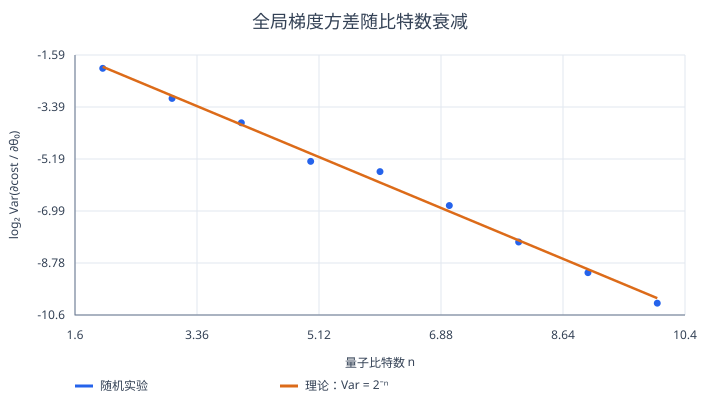

In [11]:
visualization.Plot(title="全局梯度方差随比特数衰减", xlabel="量子比特数 n", ylabel="log₂ Var(∂cost / ∂θ₀)").scatter(qubits, [log2(value) for value in variances], label="随机实验").line(qubits, [-n for n in qubits], label="理论：Var = 2⁻ⁿ")

图中越往下，表示不同初始化之间的梯度波动越小。这说明优化器看到的梯度更容易很小；但方差图本身不等于完整的训练效果或计算复杂度结论。